# Mega Data Center Site Suitability by ZIP Code
*Side project — initial research & baseline model (Nov 2026)*

**Goal:** given a US ZIP code, estimate how suitable it is for a mega (≥100 MW, hyperscale-class) data center using only public data.

## 1. Definitions first (thanks, Aaron)
Pulled from YellowDig feedback v0:

| Term | v0 definition |
|---|---|
| **Mega data center** | Hyperscale / large colocation campus, roughly ≥100 MW IT load, built by a hyperscaler or large wholesale operator |
| **Good site** | Good *for the developer/operator*: cheap, abundant, reliable power; fiber reach; low cooling load; low hazard; land available. Community impact is a separate lens (see §9) |
| **Predict** | *Revealed preference*: learn P(ZIP has an existing data-center cluster nearby) from where operators already chose to build, then use the model to find ZIPs that **look like** those places but don't have one yet ("whitespace") |
| **Unit** | Census ZCTA (ZIP Code Tabulation Area), ~33.6k in the 50 states + DC |

**Label used (v1):** `has_hyperscale_25km` = a ZIP within 25 km of one of **116 curated hyperscale / AI campuses** (≥100 MW class: Google, Microsoft, AWS, Meta, Apple, Stargate, xAI, QTS, Switch, Vantage, Aligned, …; operating, under construction, or announced). The list lives in `data/labels/hyperscale_campuses.csv` and is geocoded to the city (or county) centroid. Stricter variants are also in the file: `has_hyperscale_operating_25km` (operating only) and `has_gw_campus_50km` (1 GW+ campuses). The v0 label `has_major_dc_25km` (OSM + PeeringDB, mostly metro colocation) is kept for comparison.

> ⚠️ A revealed-preference label inherits history (e.g., Northern Virginia was chosen partly because of 1990s fiber). It tells you *where data centers are*, not *where they should be*. That is why we look at the model's false positives — high-score ZIPs with no data center — as candidate sites.

## 2. Data sources (all public, already downloaded to `data/raw/`)

| Driver | Source | Grain | Features built |
|---|---|---|---|
| Geography | Census 2023 ZCTA Gazetteer | ZIP | lat/lon, land & water area |
| ZIP→county | Census 2020 ZCTA–County relationship file | ZIP | primary county |
| Population / land-pressure proxy | Census Pop. Estimates Vintage 2024 | County | population, density, growth 2020–24 |
| Power cost | EIA Electric Power Monthly Tbl 5.6.B (YTD Sep 2026) | State | industrial & commercial ¢/kWh |
| Power supply & grid | EIA-860 2025 (plants + operating generators) | Plant (lat/lon) | MW within 50/100 km, clean-energy share, max grid kV nearby, distance to ≥500 MW plant, distance to gas-pipeline-served plant |
| Connectivity | PeeringDB facilities, IXPs | Facility (lat/lon) | distance to nearest facility / IX, networks within 50 km |
| Cooling & water | NOAA nClimDiv county series, 1995–2024 mean | County | cooling degree days, avg max temp, precipitation, Palmer drought index |
| **Labels** | OpenStreetMap (`telecom=data_center`, `building=data_center`) + PeeringDB | Site (lat/lon) | data-center counts within 10/25 km, major-operator flag |

Rebuild everything with `python3 src/build_features.py .` from the project folder.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score, RocCurveDisplay
from sklearn.cluster import KMeans
from sklearn.inspection import permutation_importance

pd.set_option("display.max_columns", 60); pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
df  = pd.read_csv("data/processed/zip_features.csv", dtype={"zip": str, "county_fips": str})
dcs = pd.read_csv("data/processed/datacenters_combined.csv")
camp = pd.read_csv("data/processed/hyperscale_campuses_geocoded.csv")
print(df.shape, "ZIPs |", len(dcs), "data-center points |", dcs.major_operator.sum(), "major-operator points |", len(camp), "curated hyperscale campuses")
df.head()

(33642, 40) ZIPs | 2598 data-center points | 1002 major-operator points | 116 curated hyperscale campuses


,zip,lat,lon,land_sqmi,water_sqmi,county_fips,county_name,state,county_pop_2024,county_pop_growth_20_24,county_pop_density,elec_price_industrial_c_kwh,elec_price_commercial_c_kwh,gen_mw_50km,clean_mw_50km,gen_mw_100km,clean_mw_100km,n_plants_50km,max_grid_kv_50km,clean_share_100km,dist_500mw_plant_km,dist_gas_pipeline_plant_km,dist_peeringdb_fac_km,dist_ix_km,networks_50km,dc_count_10km,dc_count_25km,major_dc_count_25km,dist_nearest_dc_km,cooling_degree_days,avg_tmax_f,annual_precip_in,drought_pdsi,has_dc_10km,has_major_dc_25km,hyperscale_count_25km,dist_hyperscale_km,has_hyperscale_25km,has_hyperscale_operating_25km,has_gw_campus_50km
0,01001,42.062368,-72.625754,11.292,0.821,25013,Hampden County,MA,464151.0,0.000942,752.264568,19.84,24.56,2014.6,673.4,18027.0,6416.8,191,345.0,0.355955,17.803417,2.451454,6.609517,6.644029,17,4,4,0,6.609517,509.566667,59.378611,49.813667,0.282778,1,0,0,321.732651,0,0,0
1,01002,42.377212,-72.464795,53.256,1.653,25015,Hampshire County,MA,165399.0,0.113131,313.709610,19.84,24.56,3631.6,1980.6,10946.9,3950.6,239,345.0,0.360888,20.302435,24.888048,30.971176,31.129310,16,0,0,0,30.971176,475.500000,58.884722,49.490333,0.416000,0,0,0,346.909592,0,0,0
2,01003,42.391883,-72.523584,0.804,0.005,25015,Hampshire County,MA,165399.0,0.113131,313.709610,19.84,24.56,3854.0,2634.1,10872.3,3902.2,222,345.0,0.358912,21.607482,25.520654,31.407482,31.691331,16,0,0,0,31.407482,475.500000,58.884722,49.490333,0.416000,0,0,0,343.168677,0,0,0
3,01005,42.418884,-72.112077,43.189,0.257,25027,Worcester County,MA,881248.0,0.028184,583.346407,19.84,24.56,3486.8,1962.9,14042.8,4198.5,278,345.0,0.298979,36.378168,30.128173,30.783668,51.341532,12,0,0,0,30.783668,469.333333,58.800000,49.543000,0.518639,0,0,0,375.367561,0,0,0
4,01007,42.283935,-72.400409,54.869,2.679,25015,Hampshire County,MA,165399.0,0.113131,313.709610,19.84,24.56,3906.3,2152.9,13399.3,4144.1,270,345.0,0.309277,13.191538,17.283891,24.158897,24.158897,22,0,4,0,24.158897,475.500000,58.884722,49.490333,0.416000,0,0,0,347.764561,0,0,0


## 3. Exploratory analysis

In [2]:
missing = df.isna().mean().sort_values(ascending=False)
print("Share missing (top):\n", missing[missing > 0].round(3))
print("\nLabel balance:\n", df[["has_dc_10km", "has_major_dc_25km"]].mean().round(3))

Share missing (top):
 cooling_degree_days        0.012
drought_pdsi               0.012
county_pop_density         0.009
county_pop_2024            0.009
county_pop_growth_20_24    0.009
annual_precip_in           0.005
avg_tmax_f                 0.005
dtype: float64

Label balance:
 has_dc_10km          0.155
has_major_dc_25km    0.132
dtype: float64


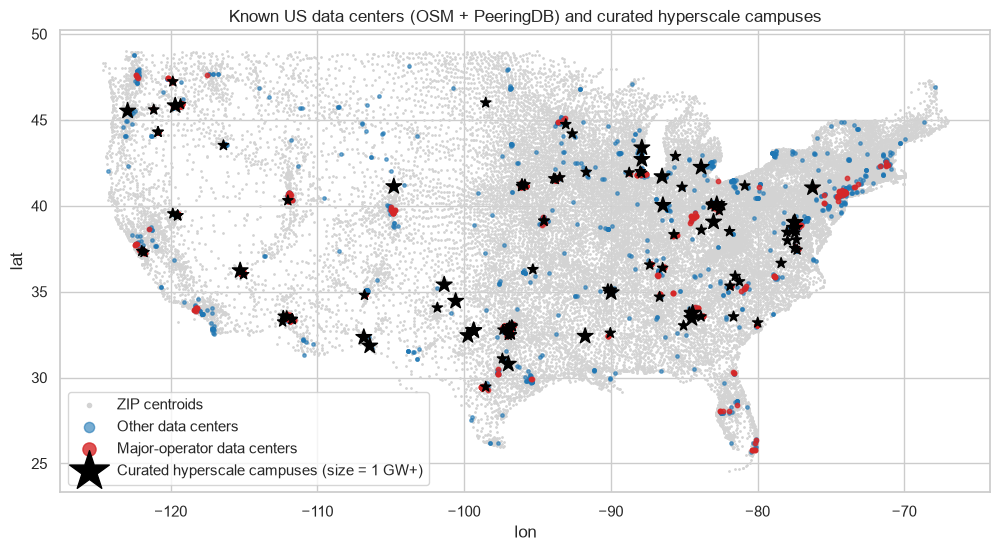

In [3]:
fig, ax = plt.subplots(figsize=(12, 6))
conus = df[(df.lon > -125) & (df.lat < 50) & (df.lat > 24)]
ax.scatter(conus.lon, conus.lat, s=1, c="lightgray", label="ZIP centroids")
d = dcs[(dcs.lon > -125) & (dcs.lat < 50) & (dcs.lat > 24)]
ax.scatter(d[~d.major_operator].lon, d[~d.major_operator].lat, s=6, c="tab:blue", alpha=.6, label="Other data centers")
ax.scatter(d[d.major_operator].lon, d[d.major_operator].lat, s=10, c="tab:red", alpha=.8, label="Major-operator data centers")
c = camp[camp.lon > -125]
ax.scatter(c.lon, c.lat, s=c.scale.map({"1GW+": 140, "100MW+": 60}), marker="*", c="black", label="Curated hyperscale campuses (size = 1 GW+)")
ax.set_title("Known US data centers (OSM + PeeringDB) and curated hyperscale campuses"); ax.legend(markerscale=3); ax.set_xlabel("lon"); ax.set_ylabel("lat")
plt.show()

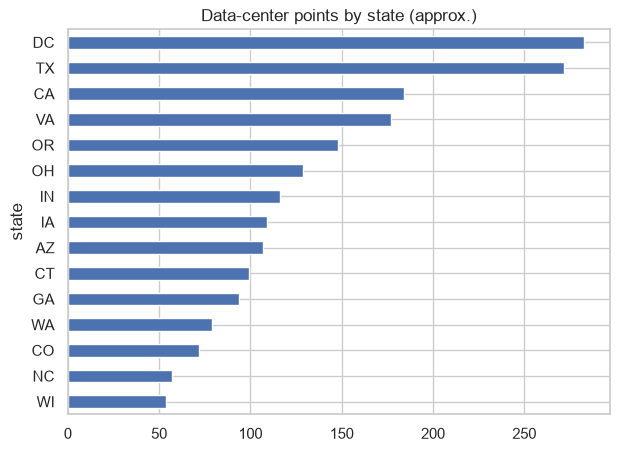

In [4]:
top = (dcs.assign(lat_r=dcs.lat.round(0), lon_r=dcs.lon.round(0))
          .merge(df[["lat", "lon", "state"]].assign(lat_r=df.lat.round(0), lon_r=df.lon.round(0))
                 .drop_duplicates(["lat_r", "lon_r"])[["lat_r", "lon_r", "state"]], on=["lat_r", "lon_r"], how="left"))
top.state.value_counts().head(15).plot.barh(figsize=(7, 5), title="Data-center points by state (approx.)").invert_yaxis()
plt.show()

### Feature sets — and a leakage warning
The connectivity features (`dist_peeringdb_fac_km`, `dist_ix_km`, `networks_50km`) come from the **same PeeringDB data that partly defines the label**. Using them would let the model "cheat". The main model therefore uses only **non-leaky site fundamentals**; the leaky set is reported separately so you can see the gap.

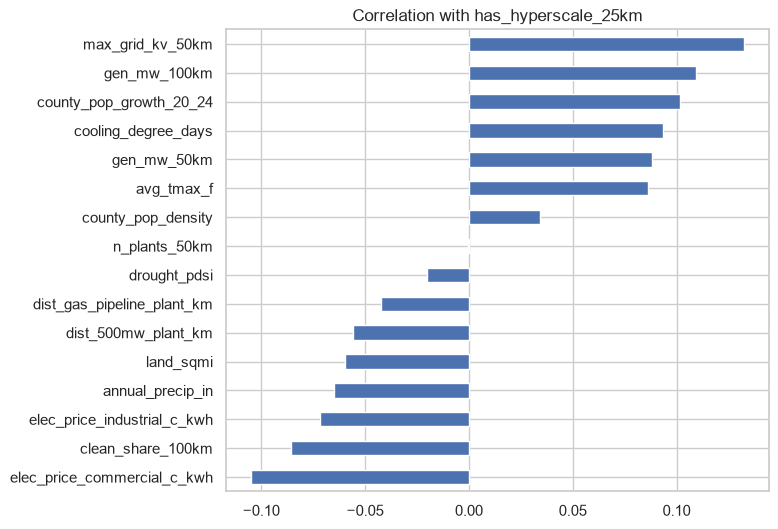

In [5]:
TARGET = "has_hyperscale_25km"
FUND = ["land_sqmi", "county_pop_density", "county_pop_growth_20_24",
        "elec_price_industrial_c_kwh", "elec_price_commercial_c_kwh",
        "gen_mw_50km", "gen_mw_100km", "clean_share_100km", "n_plants_50km", "max_grid_kv_50km",
        "dist_500mw_plant_km", "dist_gas_pipeline_plant_km",
        "cooling_degree_days", "avg_tmax_f", "annual_precip_in", "drought_pdsi"]
LEAKY = FUND + ["dist_peeringdb_fac_km", "dist_ix_km", "networks_50km"]

X, y, groups = df[FUND], df[TARGET], df["state"]
corr = df[FUND + [TARGET]].corr(numeric_only=True)[TARGET].drop(TARGET).sort_values()
corr.plot.barh(figsize=(7, 6), title=f"Correlation with {TARGET}"); plt.show()

## 4. Baseline: logistic regression with a stats summary (for Nicholas)
Logit on standardized fundamentals. McFadden pseudo-R² is the logistic analogue of R². A second, deliberately naive model uses **only what the ZIP code itself gives you** (lat/lon/area) to show how little the ZIP alone explains.

In [6]:
def logit_summary(cols, label):
    d = df[cols + [TARGET]].dropna()
    Xs = (d[cols] - d[cols].mean()) / d[cols].std()
    m = sm.Logit(d[TARGET], sm.add_constant(Xs)).fit(disp=0)
    print(f"{label}: n={len(d):,}  McFadden pseudo-R² = {m.prsquared:.3f}")
    return m

m_zip_only = logit_summary(["lat", "lon", "land_sqmi"], "ZIP-geometry only")
m_fund = logit_summary(FUND, "Site fundamentals")
m_fund.summary2().tables[1].sort_values("z", key=abs, ascending=False).round(3)

ZIP-geometry only: n=33,642  McFadden pseudo-R² = 0.058
Site fundamentals: n=32,955  McFadden pseudo-R² = 0.233


,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
const,-4.110,0.056,-73.305,0.000,-4.220,-4.000
annual_precip_in,-0.769,0.035,-21.928,0.000,-0.838,-0.701
land_sqmi,-1.595,0.100,-16.030,0.000,-1.790,-1.400
dist_500mw_plant_km,-1.071,0.077,-13.997,0.000,-1.221,-0.921
elec_price_commercial_c_kwh,-1.032,0.079,-13.063,0.000,-1.187,-0.877
county_pop_growth_20_24,0.299,0.025,11.969,0.000,0.250,0.348
max_grid_kv_50km,0.375,0.032,11.549,0.000,0.311,0.438
dist_gas_pipeline_plant_km,-0.593,0.054,-10.888,0.000,-0.700,-0.487
cooling_degree_days,-0.835,0.086,-9.718,0.000,-1.004,-0.667
avg_tmax_f,0.977,0.102,9.581,0.000,0.777,1.176


## 5. Predictive model with spatially honest validation
Random K-fold would leak neighbouring ZIPs (which share almost the same features and labels) between train and test. We use **GroupKFold by state** so the model is always scored on states it has never seen.

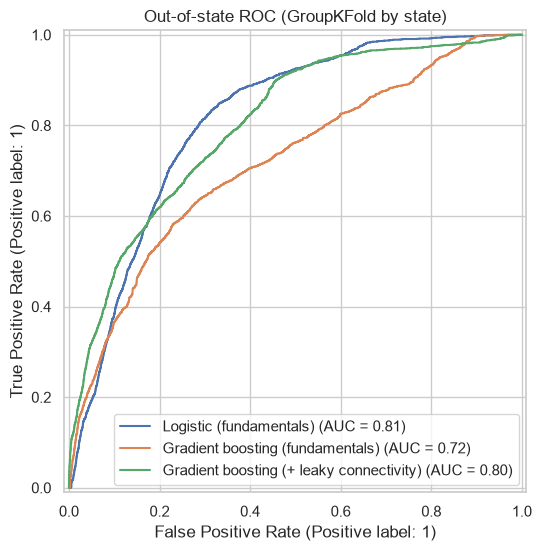

,model,ROC AUC,PR AUC,base rate
0,Logistic (fundamentals),0.812,0.173,0.061
1,Gradient boosting (fundamentals),0.718,0.167,0.061
2,Gradient boosting (+ leaky connectivity),0.802,0.264,0.061


In [7]:
cv = GroupKFold(n_splits=5)
models = {
    "Logistic (fundamentals)": (make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                              LogisticRegression(max_iter=2000, class_weight="balanced")), FUND),
    "Gradient boosting (fundamentals)": (HistGradientBoostingClassifier(max_iter=300, learning_rate=.05,
                                         class_weight="balanced", random_state=42), FUND),
    "Gradient boosting (+ leaky connectivity)": (HistGradientBoostingClassifier(max_iter=300, learning_rate=.05,
                                         class_weight="balanced", random_state=42), LEAKY),
}
oof, rows = {}, []
fig, ax = plt.subplots(figsize=(6, 6))
for name, (mdl, cols) in models.items():
    p = cross_val_predict(mdl, df[cols], y, cv=cv, groups=groups, method="predict_proba")[:, 1]
    oof[name] = p
    rows.append({"model": name, "ROC AUC": roc_auc_score(y, p), "PR AUC": average_precision_score(y, p),
                 "base rate": y.mean()})
    RocCurveDisplay.from_predictions(y, p, name=name, ax=ax)
plt.title("Out-of-state ROC (GroupKFold by state)"); plt.show()
pd.DataFrame(rows).round(3)

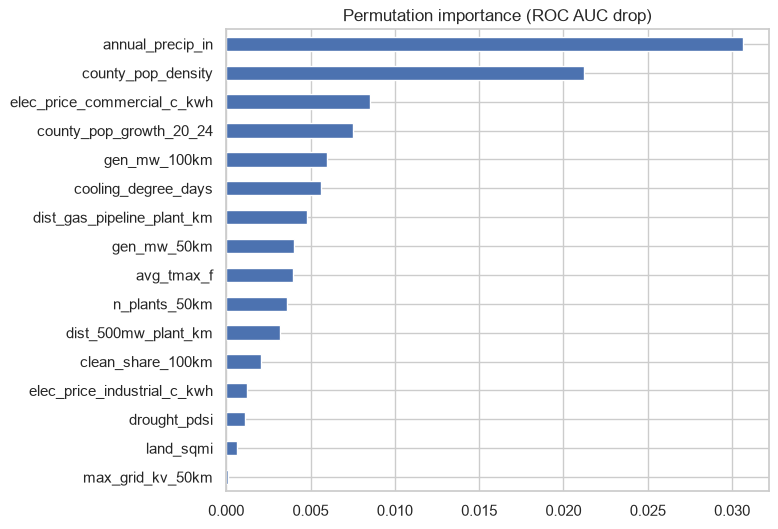

In [8]:
gb = HistGradientBoostingClassifier(max_iter=300, learning_rate=.05, class_weight="balanced", random_state=42)
gb.fit(X, y)
imp = permutation_importance(gb, X.sample(5000, random_state=0), y.loc[X.sample(5000, random_state=0).index],
                             n_repeats=5, random_state=0, scoring="roc_auc")
pd.Series(imp.importances_mean, index=FUND).sort_values().plot.barh(figsize=(7, 6),
    title="Permutation importance (ROC AUC drop)"); plt.show()
df["score"] = oof["Gradient boosting (fundamentals)"]
df["score_pctile"] = df.score.rank(pct=True).round(3)

### Label comparison: does the curated label change what the model learns?
Same logistic model, same fundamentals, same out-of-state CV — only the label changes.

,label,positives,base rate,ROC AUC,PR AUC
0,has_major_dc_25km,4424,0.132,0.899,0.577
1,has_hyperscale_25km,2040,0.061,0.812,0.173
2,has_hyperscale_operating_25km,1552,0.046,0.801,0.142
3,has_gw_campus_50km,1550,0.046,0.714,0.088


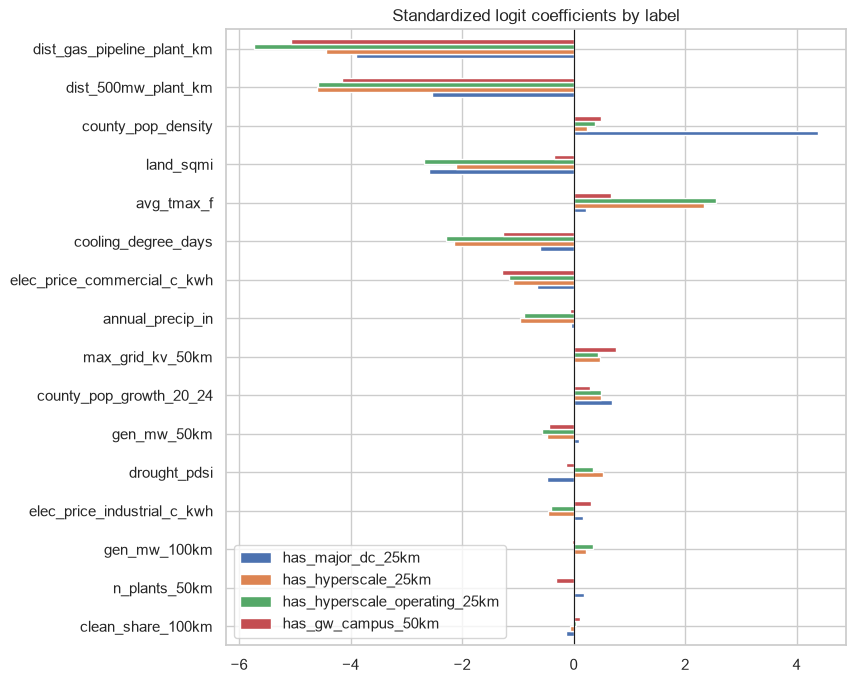

In [9]:
labels = ["has_major_dc_25km", "has_hyperscale_25km", "has_hyperscale_operating_25km", "has_gw_campus_50km"]
lr = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
rows, coefs = [], {}
for lab in labels:
    p = cross_val_predict(lr, df[FUND], df[lab], cv=cv, groups=groups, method="predict_proba")[:, 1]
    rows.append({"label": lab, "positives": int(df[lab].sum()), "base rate": df[lab].mean(),
                 "ROC AUC": roc_auc_score(df[lab], p), "PR AUC": average_precision_score(df[lab], p)})
    coefs[lab] = pd.Series(lr.fit(df[FUND], df[lab])[-1].coef_[0], index=FUND)
display(pd.DataFrame(rows).round(3))
coefs = pd.DataFrame(coefs)
coefs.loc[coefs.abs().max(axis=1).sort_values().index].plot.barh(figsize=(8, 8), title="Standardized logit coefficients by label")
plt.axvline(0, c="k", lw=.8); plt.show()

In [10]:
# Sanity check: where do the curated campuses score? (out-of-state predictions)
chk = camp.copy()
t = __import__("sklearn.neighbors", fromlist=["BallTree"]).BallTree(np.deg2rad(df[["lat", "lon"]].values), metric="haversine")
chk["nearest_zip"] = df.zip.values[t.query(np.deg2rad(chk[["lat", "lon"]].values), k=1)[1][:, 0]]
chk = chk.merge(df[["zip", "score", "score_pctile"]], left_on="nearest_zip", right_on="zip")
print("Median score percentile of campus ZIPs:", chk.score_pctile.median())
chk.sort_values("score")[["operator", "campus", "state", "status", "scale", "score", "score_pctile"]].head(12).round(3)

Median score percentile of campus ZIPs: 0.807


,operator,campus,state,status,scale,score,score_pctile
48,Meta,Prineville,OR,operating,100MW+,0.001,0.104
74,Apple,Prineville,OR,operating,100MW+,0.001,0.104
96,QTS,Hall County,TX,announced,1GW+,0.001,0.131
30,Microsoft,El Mirage,AZ,operating,100MW+,0.001,0.184
78,OpenAI/Oracle (Stargate),Abilene,TX,operating,1GW+,0.001,0.194
94,QTS,Phoenix,AZ,operating,100MW+,0.001,0.230
29,Microsoft,Goodyear,AZ,operating,100MW+,0.001,0.235
33,Microsoft,Northlake,IL,operating,100MW+,0.002,0.274
68,Meta,Hyperion (Richland Parish),LA,under_construction,1GW+,0.002,0.311
113,Various,Santa Clara,CA,operating,100MW+,0.003,0.331


## 6. Clustering ZIPs with similar site profiles (Ravi's idea)
K-means on standardized fundamentals; we then check which clusters concentrate existing data centers.

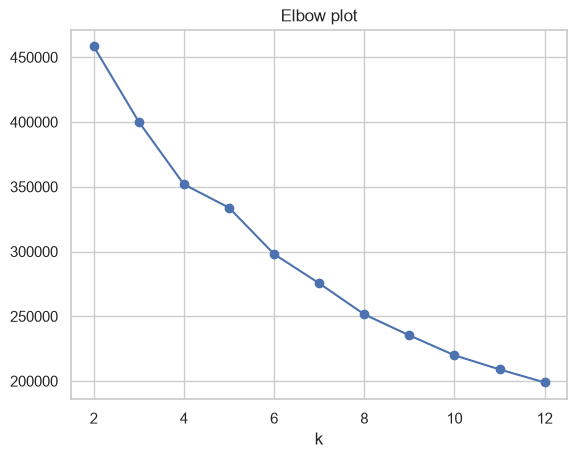

In [11]:
Z = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit_transform(df[FUND])
inertia = [KMeans(k, n_init=10, random_state=0).fit(Z).inertia_ for k in range(2, 13)]
plt.plot(range(2, 13), inertia, marker="o"); plt.title("Elbow plot"); plt.xlabel("k"); plt.show()

In [12]:
K = 6
df["cluster"] = KMeans(K, n_init=10, random_state=0).fit_predict(Z)
profile = df.groupby("cluster").agg(n_zips=("zip", "size"), dc_rate=(TARGET, "mean"),
    price_ind=("elec_price_industrial_c_kwh", "median"), gen_mw_100km=("gen_mw_100km", "median"),
    max_kv=("max_grid_kv_50km", "median"), cdd=("cooling_degree_days", "median"),
    pop_density=("county_pop_density", "median"), pdsi=("drought_pdsi", "median"),
    example_states=("state", lambda s: ", ".join(s.value_counts().index[:4])))
profile.sort_values("dc_rate", ascending=False).round(2)

,n_zips,dc_rate,price_ind,gen_mw_100km,max_kv,cdd,pop_density,pdsi,example_states
cluster,,,,,,,,,
4,9049,0.11,7.60,8614.1,345.0,2238.63,113.53,-0.19,"TX, FL, GA, NC"
0,4799,0.06,17.88,19163.4,480.0,896.50,1353.53,-0.00,"CA, NJ, MA, NY"
1,19322,0.04,9.31,4975.7,230.0,704.17,60.20,0.62,"PA, OH, NY, IL"
2,97,0.00,38.18,509.8,69.0,NaN,140.92,NaN,HI
3,243,0.00,23.40,15.7,12.4,NaN,0.45,NaN,AK
5,132,0.00,10.31,35683.4,480.0,1156.03,73292.61,-0.01,NY


## 7. Whitespace: high-scoring ZIPs with **no** major data center within 25 km
These are the interesting outputs — places that look like existing data-center markets on fundamentals but haven't been built out (or are, but OSM/PeeringDB don't know yet).

In [13]:
cols = ["zip", "county_name", "state", "score", "elec_price_industrial_c_kwh", "gen_mw_100km",
        "max_grid_kv_50km", "cooling_degree_days", "county_pop_density", "dist_nearest_dc_km"]
# Mega campuses need cheap land: keep exurban/rural ZIPs (county density < 500 people/sq mi, > 5 sq mi)
whitespace = df[(df[TARGET] == 0) & (df.land_sqmi > 5) & (df.county_pop_density < 500)].sort_values("score", ascending=False)
whitespace[cols].head(25).round(2)

,zip,county_name,state,score,elec_price_industrial_c_kwh,gen_mw_100km,max_grid_kv_50km,cooling_degree_days,county_pop_density,dist_nearest_dc_km
30304,89026,Clark County,NV,0.93,8.85,15628.1,525.0,2692.43,303.98,34.52
7874,25405,Berkeley County,WV,0.93,8.25,6959.6,480.0,932.90,424.38,33.44
26813,76426,Wise County,TX,0.93,6.79,14301.0,350.0,2545.03,89.87,51.09
7879,25420,Berkeley County,WV,0.93,8.25,7470.2,500.0,932.90,424.38,29.24
26693,76073,Wise County,TX,0.93,6.79,15631.2,350.0,2545.03,89.87,37.91
26293,75114,Kaufman County,TX,0.93,6.79,14074.0,345.0,2600.83,253.40,23.93
7884,25428,Berkeley County,WV,0.93,8.25,7073.5,500.0,932.90,424.38,32.84
8810,28174,Union County,NC,0.92,8.01,19820.0,230.0,1710.13,416.26,26.25
25971,74131,Creek County,OK,0.92,7.06,11419.2,345.0,1919.13,77.87,13.15
25894,74015,Rogers County,OK,0.91,7.06,9918.0,345.0,1916.50,150.01,14.13


In [14]:
whitespace.groupby("state").score.apply(lambda s: (s > .8).sum()).sort_values(ascending=False).head(15)

state
WV    16
SC    13
OK    12
TX     9
WI     6
NC     6
KY     3
NV     3
AK     0
NE     0
NH     0
NJ     0
NM     0
NY     0
OH     0
Name: score, dtype: int64

### Key findings (v1, curated hyperscale label)
- **The curated label changes what the model learns.** With the v0 label (mostly metro colocation), urban density was the strongest driver (standardized coef ≈ 2.7). With the hyperscale label it falls to ≈ 0.2, and **power and climate take over**: distance to a ≥500 MW plant, high-voltage grid nearby, lower commercial power price, and drier climates.
- **Fit is lower, but the problem is more honest:** McFadden pseudo-R² ≈ 0.23 (ZIP geometry alone ≈ 0.06). Out-of-state ROC AUC ≈ 0.81, and PR AUC ≈ 0.17 against a 6% base rate, roughly 3× lift.
- **Logistic beats gradient boosting** out of state (0.81 vs 0.72). With only ~116 campuses clustered in a few markets, the tree model memorises state-specific patterns that don't transfer.
- **Leaky connectivity features no longer help much** (0.80): hyperscale campuses are *not* where the interconnection hubs are.
- **Where the model misses is informative.** Phoenix-area (AZ), Prineville OR, Abilene TX, and Richland Parish LA score low out of state. Those sites were won on things v1 doesn't measure: tax incentives, cheap large parcels, water rights or dry-air cooling, and dedicated new generation. These are the next features to add.
- **Whitespace candidates** (high score, no campus within 25 km, exurban) cluster in Berkeley County WV, the DFW exurbs (Wise and Kaufman TX), the Tulsa area (Creek and Rogers OK), Anson/Union NC, South Carolina, and Dane County WI.

## 8. Score any ZIP

In [15]:
def score_zip(zip5, exclude_states=()):
    zip5 = str(zip5).zfill(5)
    r = df[df.zip == zip5]
    if r.empty:
        return f"{zip5}: not a residential ZCTA (PO-box/business ZIPs have no ZCTA — try a nearby ZIP)"
    r = r.iloc[0]
    if r.state in exclude_states:          # for Josephine 🙂
        return f"{zip5} ({r.state}): excluded by request"
    out = r[["zip", "county_name", "state", "score", "score_pctile", "cluster"] + FUND +
            ["dc_count_25km", "major_dc_count_25km", "dist_nearest_dc_km"]]
    return out.to_frame("value")

score_zip("20147")   # Ashburn, VA — the world's largest data-center market

,value
zip,20147
county_name,Loudoun County
state,VA
score,0.575304
score_pctile,0.962
cluster,4
land_sqmi,19.844
county_pop_density,859.701747
county_pop_growth_20_24,0.048867
elec_price_industrial_c_kwh,10.05


In [16]:
pd.concat({z: score_zip(z).value for z in ["20147", "50325", "97058", "61820", "85339", "80202"]}, axis=1).T[
    ["county_name", "state", "score", "score_pctile", "cluster", "elec_price_industrial_c_kwh",
     "gen_mw_100km", "cooling_degree_days", "major_dc_count_25km"]]

,county_name,state,score,score_pctile,cluster,elec_price_industrial_c_kwh,gen_mw_100km,cooling_degree_days,major_dc_count_25km
20147,Loudoun County,VA,0.575304,0.962,4,10.05,14086.3,1059.433333,214
50325,Polk County,IA,0.73401,0.979,1,7.79,6897.9,988.333333,26
97058,Wasco County,OR,0.041738,0.752,1,8.39,9607.9,352.866667,4
61820,Champaign County,IL,0.048892,0.77,1,10.61,11465.3,1029.433333,0
85339,Maricopa County,AZ,0.001334,0.218,4,7.94,25924.1,3794.133333,11
80202,Denver County,CO,0.443881,0.948,1,9.68,6617.4,774.9,11


In [17]:
df.to_csv("data/processed/zip_scores.csv", index=False)
print("Saved data/processed/zip_scores.csv")

Saved data/processed/zip_scores.csv


## 9. Gaps, caveats and next steps (two-week plan)

**Known data gaps**
- **Natural hazards** — FEMA National Risk Index (county) blocks scripted download; grab `NRI_Table_Counties.zip` manually from hazards.fema.gov/nri/data-resources and join on `county_fips`.
- **Transmission & substations** — HIFLD Open was retired in 2025; plant grid-voltage from EIA-860 is used as a proxy. Upgrade: OSM `power=substation` / `power=line` via Overpass, or interconnection-queue data (LBNL "Queued Up").
- **Fiber** — FCC Broadband Data Collection (fiber availability by location) needs a free account; long-haul fiber routes are not public.
- **Land cost** — county density is a proxy. Upgrade: USDA NASS land values (state) or ACS median home value (ZIP; needs a free Census API key).
- **Water stress** — PDSI/precip are proxies. Upgrade: WRI Aqueduct baseline water stress.
- **Incentives & policy** — state sales-tax exemptions for data-center equipment (a big real-world driver) — hand-code a ~50-row table.
- **Community acceptance** (Jeffrey's point) — moratoria and local opposition; could proxy with news/zoning-hearing counts. Not in v0.
- **Label quality** — OSM coverage is uneven and PeeringDB favors interconnection-heavy colo sites over remote hyperscale campuses. A hand-curated list of announced ≥100 MW campuses would be the best label upgrade.

**Next steps**
1. Day 1–3: lock definitions; curate a hyperscale-campus label list.
2. Day 4–7: add NRI, substations, tax incentives, ZIP-level ACS.
3. Day 8–10: re-train, calibrate, compare with an expert-weighted score.
4. Day 11–14: simple app (Streamlit) — type a ZIP, get score + "why".